# Phase 2 · Hyper-parameter optimisation

Tunes the three phase 1 architectures (Logistic Regression, Naive Bayes, Decision Tree) and adds the two tree ensembles recommended by the brief (Random Forest and Gradient Boosting), with a most-frequent `DummyClassifier` as the floor.

- **Holdout test**: the phase 1 split (one of five polygon folds), untouched during tuning, so the results are comparable with phase 1.
- **Validation**: `StratifiedGroupKFold` on the training set, 5 folds repeated with 2 seeds = **10 validations** per candidate. Polygons are never split; the class proportions of every fold stay as close to the training set as whole polygons allow.
- **Objective**: macro-F1 over the classes with reference pixels (2 to 9; class 10 has a single polygon and cannot be validated). Accuracy, kappa and balanced accuracy are tracked alongside.
- **Search**: exhaustive finite grids. Random Forest and Gradient Boosting are tuned on a class-stratified 25 % subsample of the training pixels with the same folds; every selected model is then refit on the full training set.
- **Outputs**: `outputs/phase2/` and one MLflow run per model (`phase2-<model>`).

In [1]:
import gc
import io
import json
import os
import time
import warnings
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import skops.io as sio
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, cohen_kappa_score,
    confusion_matrix, f1_score, make_scorer, precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sqlalchemy import URL, create_engine, text

# The parallel workers of the search import the feature transformer from this folder.
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(Path.cwd()), os.environ.get("PYTHONPATH")]))
from sentinel2_features import BANDS as FEATURE_BANDS, SpectralFeatures

DATASET = "T18NWL_20260810T152649"
BANDS = [band.strip() for band in os.environ["BAND_NAMES"].split(",")]
assert tuple(BANDS) == FEATURE_BANDS, "band order differs from sentinel2_features.BANDS"
SEED = 42
HOLDOUT_FOLDS = 5          # same holdout as phase 1: one fold of five polygons groups
CV_FOLDS = 5               # validation folds inside the training set
CV_SEEDS = [SEED, SEED + 1]  # 2 repetitions -> 10 validations per candidate
SUBSAMPLE_FRACTION = 0.25  # training pixels used to tune Random Forest and Gradient Boosting
N_JOBS = 4                 # parallel candidates; the container has 10 cores and ~8 GB of RAM
OUTPUTS = Path("outputs/phase2")
OUTPUTS.mkdir(parents=True, exist_ok=True)
PROGRESS = OUTPUTS / "progress.log"
PROGRESS.write_text("")

CLASS_NAMES = {
    0: "No data", 1: "Saturated or defective", 2: "Dark area pixels", 3: "Cloud shadows",
    4: "Vegetation", 5: "Not vegetated", 6: "Water", 7: "Unclassified",
    8: "Cloud medium probability", 9: "Cloud high probability", 10: "Thin cirrus", 11: "Snow",
}
# Metric warnings for classes absent from a fold (class 10) are expected and handled with labels=.
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")


def log(message):
    stamp = time.strftime("%H:%M:%S")
    print(f"[{stamp}] {message}", flush=True)
    with PROGRESS.open("a") as handle:
        handle.write(f"[{stamp}] {message}\n")

## 1. Load the training dataset

Same source and polygon join as phase 1.

In [2]:
s3 = boto3.client("s3", endpoint_url=os.environ["MLFLOW_S3_ENDPOINT_URL"])
body = s3.get_object(Bucket=os.environ["DATA_BUCKET"], Key=f"tsv/{DATASET}.tsv")["Body"].read()
samples = pd.read_csv(io.BytesIO(body), sep="\t", float_precision="round_trip")
assert list(samples.columns) == ["Latitude", "Longitude", *BANDS, "Class"], samples.columns

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ["TRAIN_DB_USER"], password=os.environ["TRAIN_DB_PASSWORD"],
    host=os.environ["TRAIN_DB_HOST"], port=int(os.environ["TRAIN_DB_PORT"]),
    database=os.environ["TRAIN_DB_NAME"],
))
with engine.connect() as connection:
    polygons = pd.read_sql(
        text('SELECT latitude AS "Latitude", longitude AS "Longitude", fid '
             "FROM extracted.polygon_pixels WHERE dataset = :dataset"),
        connection, params={"dataset": DATASET},
    )
samples = samples.merge(polygons, on=["Latitude", "Longitude"], how="left", validate="one_to_one")
assert samples["fid"].notna().all(), "samples without a polygon"
log(f"{len(samples):,} samples, {samples['fid'].nunique():,} polygons")

[14:44:23] 583,835 samples, 11,711 polygons


## 2. Holdout test (phase 1 split)

In [3]:
X, y, groups = samples[BANDS], samples["Class"], samples["fid"]
train_index, test_index = next(
    StratifiedGroupKFold(n_splits=HOLDOUT_FOLDS, shuffle=True, random_state=SEED).split(X, y, groups)
)
X_train, y_train, g_train = (part.iloc[train_index].reset_index(drop=True) for part in (X, y, groups))
X_test, y_test = X.iloc[test_index].reset_index(drop=True), y.iloc[test_index].reset_index(drop=True)
assert not set(g_train) & set(groups.iloc[test_index]), "polygon on both sides"

phase1 = json.loads(Path("outputs/phase1/metrics.json").read_text())
assert (len(y_train), len(y_test)) == (phase1["train_samples"], phase1["test_samples"]), "split differs from phase 1"

EVAL_LABELS = sorted(y_test.unique())  # classes that can be evaluated (2 to 9)
TRAIN_LABELS = sorted(y_train.unique())
log(f"train {len(y_train):,} / test {len(y_test):,}; evaluated classes {EVAL_LABELS}")

[14:44:24] train 468,989 / test 114,846; evaluated classes [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## 3. Validation folds balanced by class

`StratifiedGroupKFold` assigns whole polygons to folds while keeping the share of pixels of every class as close as possible to the training set. Two repetitions with different seeds give ten validations per candidate.

More folds were considered: with 10 folds the water class (11 training polygons, some of them large) drops to 11 pixels in one validation fold, so 5 folds × 2 repetitions keeps every fold balanced while doubling the number of validations.

In [4]:
splits, balance_rows = [], []
for repeat, seed in enumerate(CV_SEEDS):
    splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=seed)
    for fold, (fit_index, val_index) in enumerate(splitter.split(X_train, y_train, g_train)):
        assert not set(g_train.iloc[fit_index]) & set(g_train.iloc[val_index]), "polygon on both sides"
        counts = y_train.iloc[val_index].value_counts()
        assert all(counts.get(label, 0) > 0 for label in EVAL_LABELS), f"fold without an evaluated class"
        splits.append((fit_index, val_index))
        balance_rows.append({"split": len(splits) - 1, "repeat": repeat, "fold": fold, "pixels": len(val_index),
                             **{label: int(counts.get(label, 0)) for label in TRAIN_LABELS}})

balance = pd.DataFrame(balance_rows).set_index("split")
balance.to_csv(OUTPUTS / "fold_balance.csv")

# Share of each class in every validation fold against its share in the whole training set.
shares = balance[TRAIN_LABELS].div(balance["pixels"], axis=0)
reference = y_train.value_counts(normalize=True).reindex(TRAIN_LABELS)
share_table = pd.DataFrame({"training share": reference, "min fold share": shares.min(), "max fold share": shares.max()})
share_table.index.name = "Class"
share_table.round(4).to_csv(OUTPUTS / "fold_class_shares.csv")
log(f"{len(splits)} validation splits; largest deviation of a class share: "
    f"{(shares - reference).abs().max().max():.4f}")
display(balance)
share_table.round(4)

[14:44:25] 10 validation splits; largest deviation of a class share: 0.0183


,repeat,fold,pixels,2,3,4,5,6,7,8,9,10
split,,,,,,,,,,,,
0,0,0,93141,658,4891,7417,68049,2638,1042,3590,4856,0
1,0,1,93238,658,4903,7417,68049,2728,1042,3590,4851,0
2,0,2,92581,655,4911,7417,69490,428,1042,3698,4940,0
3,0,3,94441,658,5707,7412,69494,1524,1041,3701,4855,49
4,0,4,95588,658,5757,7412,69489,446,1041,5932,4853,0
5,1,0,93141,658,4891,7417,68049,2638,1042,3590,4856,0
6,1,1,93238,658,4903,7417,68049,2728,1042,3590,4851,0
7,1,2,92581,655,4911,7417,69490,428,1042,3698,4940,0
8,1,3,94441,658,5707,7412,69494,1524,1041,3701,4855,49


,training share,min fold share,max fold share
Class,,,
2,0.0070,0.0069,0.0071
3,0.0558,0.0525,0.0604
4,0.0791,0.0775,0.0801
5,0.7347,0.7270,0.7506
6,0.0166,0.0046,0.0293
7,0.0111,0.0109,0.0113
8,0.0437,0.0385,0.0621
9,0.0519,0.0508,0.0534
10,0.0001,0.0000,0.0005


Random Forest and Gradient Boosting are tuned on a class-stratified subsample that keeps the same fold assignment.

In [5]:
subsample = np.sort(y_train.groupby(y_train).sample(frac=SUBSAMPLE_FRACTION, random_state=SEED).index.to_numpy())
position = np.full(len(y_train), -1)
position[subsample] = np.arange(len(subsample))
sub_splits = []
for fit_index, val_index in splits:
    fit_sub, val_sub = position[fit_index], position[val_index]
    sub_splits.append((fit_sub[fit_sub >= 0], val_sub[val_sub >= 0]))
X_sub, y_sub = X_train.iloc[subsample].reset_index(drop=True), y_train.iloc[subsample].reset_index(drop=True)
log(f"subsample {len(y_sub):,} pixels ({SUBSAMPLE_FRACTION:.0%} of every class)")

[14:44:25] subsample 117,248 pixels (25% of every class)


## 4. Search spaces

Every estimator is a pipeline so the learned preprocessing is fitted inside each fold. `features` is `SpectralFeatures` (`sentinel2_features.py`): the ten bands, optionally `log1p`, optionally followed by NDVI, NDWI, MNDWI, NDMI and NBR.

In [6]:
SCORING = {
    "f1_macro": make_scorer(f1_score, average="macro", labels=EVAL_LABELS, zero_division=0),
    "accuracy": "accuracy",
    "kappa": make_scorer(cohen_kappa_score),
    "balanced_accuracy": make_scorer(balanced_accuracy_score),
}

SEARCHES = {
    "dummy": ("Most frequent (baseline)", Pipeline([("model", DummyClassifier(strategy="most_frequent"))]), {}, "full"),
    "logistic_regression": (
        "Logistic Regression",
        Pipeline([("features", SpectralFeatures()), ("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=3000))]),
        {"features__indices": [False, True], "model__C": [0.01, 0.1, 1, 10],
         "model__class_weight": [None, "balanced"]},
        "full",
    ),
    "naive_bayes": (
        "Naive Bayes",
        Pipeline([("features", SpectralFeatures()), ("model", GaussianNB())]),
        {"features__indices": [False, True], "features__log": [False, True],
         "model__var_smoothing": np.logspace(-12, -3, 10).tolist()},
        "full",
    ),
    "decision_tree": (
        "Decision Tree",
        Pipeline([("model", DecisionTreeClassifier(random_state=SEED))]),
        {"model__max_depth": [10, 15, 20, None], "model__min_samples_leaf": [1, 5, 20, 50],
         "model__criterion": ["gini", "entropy"], "model__class_weight": [None, "balanced"]},
        "full",
    ),
    "random_forest": (
        "Random Forest",
        Pipeline([("model", RandomForestClassifier(n_estimators=200, n_jobs=N_JOBS, random_state=SEED))]),
        {"model__max_depth": [20, None], "model__max_features": ["sqrt", 0.5],
         "model__min_samples_leaf": [1, 5], "model__class_weight": [None, "balanced_subsample"]},
        "subsample",
    ),
    "gradient_boosting": (
        "Gradient Boosting (HistGradientBoosting)",
        Pipeline([("model", HistGradientBoostingClassifier(
            max_iter=500, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED))]),
        {"model__learning_rate": [0.05, 0.1, 0.2], "model__max_leaf_nodes": [31, 63, 127],
         "model__l2_regularization": [0.0, 1.0], "model__class_weight": [None, "balanced"]},
        "subsample",
    ),
}
pd.DataFrame([
    {"model": name, "candidates": int(np.prod([len(v) for v in grid.values()])) if grid else 1,
     "fits": (int(np.prod([len(v) for v in grid.values()])) if grid else 1) * len(splits), "data": data}
    for name, _, grid, data in SEARCHES.values()
])

,model,candidates,fits,data
0,Most frequent (baseline),1,10,full
1,Logistic Regression,16,160,full
2,Naive Bayes,40,400,full
3,Decision Tree,64,640,full
4,Random Forest,16,160,subsample
5,Gradient Boosting (HistGradientBoosting),36,360,subsample


## 5. Grid search with the 10 validations

In [7]:
METRICS = list(SCORING)
searches = {}
for key, (name, estimator, grid, data) in SEARCHES.items():
    X_fit, y_fit, cv = (X_sub, y_sub, sub_splits) if data == "subsample" else (X_train, y_train, splits)
    started = time.time()
    search = GridSearchCV(
        estimator, grid, scoring=SCORING, refit=False, cv=cv, return_train_score=True,
        n_jobs=1 if key == "random_forest" else N_JOBS, error_score="raise",
    )
    search.fit(X_fit, y_fit)
    seconds = time.time() - started

    table = pd.DataFrame(search.cv_results_)
    table.to_csv(OUTPUTS / f"cv_results_{key}.csv", index=False)
    best = int(table["mean_test_f1_macro"].idxmax())
    split_scores = [table.loc[best, f"split{i}_test_f1_macro"] for i in range(len(cv))]
    searches[key] = {
        "name": name, "data": data, "candidates": len(table), "search_seconds": round(seconds),
        "params": table.loc[best, "params"], "split_f1_macro": split_scores,
        **{f"cv_{m}_mean": float(table.loc[best, f"mean_test_{m}"]) for m in METRICS},
        **{f"cv_{m}_std": float(table.loc[best, f"std_test_{m}"]) for m in METRICS},
        "cv_train_f1_macro_mean": float(table.loc[best, "mean_train_f1_macro"]),
    }
    log(f"{name}: {len(table)} candidates x {len(cv)} validations in {seconds / 60:.1f} min; "
        f"best macro-F1 {searches[key]['cv_f1_macro_mean']:.4f} ± {searches[key]['cv_f1_macro_std']:.4f} "
        f"with {searches[key]['params']}")
    del search
    gc.collect()

(OUTPUTS / "best_params.json").write_text(json.dumps(
    {key: {"model": s["name"], "params": s["params"], "tuned_on": s["data"], "candidates": s["candidates"]}
     for key, s in searches.items()}, indent=2, default=str))

[14:44:27] Most frequent (baseline): 1 candidates x 10 validations in 0.0 min; best macro-F1 0.1059 ± 0.0007 with {}


[14:53:06] Logistic Regression: 16 candidates x 10 validations in 8.7 min; best macro-F1 0.6239 ± 0.0303 with {'features__indices': True, 'model__C': 1, 'model__class_weight': 'balanced'}


[14:53:39] Naive Bayes: 40 candidates x 10 validations in 0.5 min; best macro-F1 0.6040 ± 0.0251 with {'features__indices': True, 'features__log': True, 'model__var_smoothing': 1e-06}


[15:00:42] Decision Tree: 64 candidates x 10 validations in 7.0 min; best macro-F1 0.6754 ± 0.0373 with {'model__class_weight': None, 'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 20}


[15:26:34] Random Forest: 16 candidates x 10 validations in 25.9 min; best macro-F1 0.7033 ± 0.0357 with {'model__class_weight': 'balanced_subsample', 'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}


[15:36:30] Gradient Boosting (HistGradientBoosting): 36 candidates x 10 validations in 9.9 min; best macro-F1 0.7049 ± 0.0396 with {'model__class_weight': None, 'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}


1416

## 6. Refit on the full training set and evaluate on the holdout

The holdout was not used to choose anything above. Each selected configuration is refit on all 468,989 training pixels.

In [8]:
def holdout_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=EVAL_LABELS, average=None, zero_division=0)
    macro = precision_recall_fscore_support(y_true, y_pred, labels=EVAL_LABELS, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(y_true, y_pred, labels=EVAL_LABELS, average="weighted", zero_division=0)
    summary = {
        "overall_accuracy": accuracy_score(y_true, y_pred),
        "kappa": cohen_kappa_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": macro[0], "recall_macro": macro[1], "f1_macro": macro[2],
        "precision_weighted": weighted[0], "recall_weighted": weighted[1], "f1_weighted": weighted[2],
    }
    per_class = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1}, index=EVAL_LABELS)
    return summary, per_class


def trusted_types(model):
    # The model was built in this notebook; trust exactly the types skops reports as unknown.
    return sio.get_untrusted_types(data=sio.dumps(model))


mlflow.set_experiment(os.environ["MLFLOW_EXPERIMENT_NAME"])
results, per_class_f1, matrices = [], {}, {}
for key, search in searches.items():
    name = search["name"]
    model = clone(SEARCHES[key][1]).set_params(**search["params"])
    started = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - started
    predicted = model.predict(X_test)
    summary, per_class = holdout_metrics(y_test, predicted)
    train_accuracy = accuracy_score(y_train, model.predict(X_train))

    matrix = pd.DataFrame(confusion_matrix(y_test, predicted, labels=TRAIN_LABELS), index=TRAIN_LABELS, columns=TRAIN_LABELS)
    matrix.index.name, matrix.columns.name = "reference", "predicted"
    matrix.to_csv(OUTPUTS / f"confusion_matrix_{key}.csv")
    matrices[key] = matrix
    per_class.insert(0, "name", per_class.index.map(CLASS_NAMES))
    per_class.index.name = "Class"
    per_class.round(4).to_csv(OUTPUTS / f"per_class_{key}.csv")
    per_class_f1[name] = per_class["f1"]

    figure, axis = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=EVAL_LABELS, normalize="true", values_format=".2f",
        cmap="Blues", colorbar=False, ax=axis)
    axis.set(title=f"{name} · OA {summary['overall_accuracy']:.3f} · macro-F1 {summary['f1_macro']:.3f}",
             xlabel="Predicted class", ylabel="Reference class")
    figure.tight_layout()
    figure.savefig(OUTPUTS / f"confusion_matrix_{key}.png", dpi=150)
    plt.close(figure)

    with mlflow.start_run(run_name=f"phase2-{key}") as run:
        mlflow.log_params({
            "phase": 2, "model": name, "dataset": DATASET, "bands": ",".join(BANDS), "seed": SEED,
            "holdout": f"StratifiedGroupKFold by polygon, 1 of {HOLDOUT_FOLDS} folds",
            "validation": f"StratifiedGroupKFold by polygon, {CV_FOLDS} folds x {len(CV_SEEDS)} seeds",
            "tuned_on": f"{search['data']} ({len(y_sub) if search['data'] == 'subsample' else len(y_train)} pixels)",
            "candidates": search["candidates"], "objective": "macro-F1 over classes " + ",".join(map(str, EVAL_LABELS)),
            **{k: str(v) for k, v in search["params"].items()},
        })
        mlflow.log_metrics({
            **{k: v for k, v in search.items() if k.startswith("cv_")},
            **{f"test_{k}": v for k, v in summary.items()},
            "train_accuracy": train_accuracy, "fit_seconds": fit_seconds,
        })
        for artifact in (f"confusion_matrix_{key}.png", f"confusion_matrix_{key}.csv",
                         f"per_class_{key}.csv", f"cv_results_{key}.csv"):
            mlflow.log_artifact(OUTPUTS / artifact)
        mlflow.sklearn.log_model(model, name="model", skops_trusted_types=trusted_types(model),
                                 code_paths=["sentinel2_features.py"])

    results.append({"key": key, "model": name, "tuned_on": search["data"],
                    "cv_f1_macro_mean": search["cv_f1_macro_mean"], "cv_f1_macro_std": search["cv_f1_macro_std"],
                    "cv_accuracy_mean": search["cv_accuracy_mean"], "cv_kappa_mean": search["cv_kappa_mean"],
                    **{f"test_{k}": v for k, v in summary.items()},
                    "train_accuracy": train_accuracy, "fit_seconds": round(fit_seconds, 1),
                    "mlflow_run_id": run.info.run_id})
    log(f"{name}: holdout OA {summary['overall_accuracy']:.4f}, kappa {summary['kappa']:.4f}, "
        f"macro-F1 {summary['f1_macro']:.4f} (train accuracy {train_accuracy:.4f})")
    del model
    gc.collect()

2026/11/13 15:36:30 INFO mlflow.tracking.fluent: Experiment with name 'sentinel2-land-cover' does not exist. Creating a new experiment.


🏃 View run phase2-dummy at: http://mlflow:5000/#/experiments/2/runs/8b0d048bfca14a7ba04c90dc72e4273d
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[15:36:34] Most frequent (baseline): holdout OA 0.7411, kappa 0.0000, macro-F1 0.1064 (train accuracy 0.7347)


🏃 View run phase2-logistic_regression at: http://mlflow:5000/#/experiments/2/runs/45f63183016141beb4430591f766c729
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[15:37:51] Logistic Regression: holdout OA 0.8457, kappa 0.6925, macro-F1 0.5787 (train accuracy 0.8558)


🏃 View run phase2-naive_bayes at: http://mlflow:5000/#/experiments/2/runs/2ba151685d884ac3bf15b2d132d339de
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[15:37:54] Naive Bayes: holdout OA 0.8442, kappa 0.6798, macro-F1 0.5914 (train accuracy 0.8527)


🏃 View run phase2-decision_tree at: http://mlflow:5000/#/experiments/2/runs/254d4f261c714aae817e3fcd6628b634
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[15:38:00] Decision Tree: holdout OA 0.9182, kappa 0.8100, macro-F1 0.6443 (train accuracy 0.9454)


🏃 View run phase2-random_forest at: http://mlflow:5000/#/experiments/2/runs/80e494762d4e44979342999c91d87fe5
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[15:39:16] Random Forest: holdout OA 0.9212, kappa 0.8253, macro-F1 0.6685 (train accuracy 0.9668)


🏃 View run phase2-gradient_boosting at: http://mlflow:5000/#/experiments/2/runs/000dd2fbc2aa4d038ffe401a24425a5b
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[15:44:39] Gradient Boosting (HistGradientBoosting): holdout OA 0.9332, kappa 0.8445, macro-F1 0.6722 (train accuracy 0.9720)


## 7. Comparison

The model is chosen by the **cross-validated macro-F1** (mean of the 10 validations), not by the holdout. The holdout columns are the independent estimate of the chosen configurations.

In [9]:
summary = pd.DataFrame(results).sort_values("cv_f1_macro_mean", ascending=False).reset_index(drop=True)
best_key = summary.loc[summary["key"] != "dummy", "key"].iloc[0]
summary["selected"] = summary["key"] == best_key
summary.drop(columns="key").to_csv(OUTPUTS / "summary.csv", index=False)

(OUTPUTS / "metrics.json").write_text(json.dumps({
    "dataset": DATASET, "train_samples": len(y_train), "test_samples": len(y_test),
    "validation": {"folds": CV_FOLDS, "seeds": CV_SEEDS, "splits": len(splits)},
    "subsample_pixels": len(y_sub), "evaluated_classes": EVAL_LABELS, "selected": best_key,
    "models": results,
}, indent=2, default=str))
log(f"selected by cross-validated macro-F1: {summary.loc[summary['selected'], 'model'].item()}")

columns = ["model", "cv_f1_macro_mean", "cv_f1_macro_std", "test_overall_accuracy", "test_kappa",
           "test_balanced_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro",
           "test_f1_weighted", "train_accuracy", "selected"]
summary[columns].round(4)

[15:44:39] selected by cross-validated macro-F1: Gradient Boosting (HistGradientBoosting)


,model,cv_f1_macro_mean,cv_f1_macro_std,test_overall_accuracy,test_kappa,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted,train_accuracy,selected
0,Gradient Boosting (HistGradientBoosting),0.7049,0.0396,0.9332,0.8445,0.6543,0.6973,0.6543,0.6722,0.9308,0.9720,True
1,Random Forest,0.7033,0.0357,0.9212,0.8253,0.6990,0.6470,0.6990,0.6685,0.9246,0.9668,False
2,Decision Tree,0.6754,0.0373,0.9182,0.8100,0.6314,0.6624,0.6314,0.6443,0.9159,0.9454,False
3,Logistic Regression,0.6239,0.0303,0.8457,0.6925,0.6794,0.5608,0.6794,0.5787,0.8748,0.8558,False
4,Naive Bayes,0.6040,0.0251,0.8442,0.6798,0.6441,0.5712,0.6441,0.5914,0.8681,0.8527,False
5,Most frequent (baseline),0.1059,0.0007,0.7411,0.0000,0.1250,0.0926,0.1250,0.1064,0.6309,0.7347,False


In [10]:
# Phase 1 (default parameters) against phase 2 (tuned) on the same holdout.
# Phase 1 macro-F1 is recomputed over the evaluated classes from its saved confusion matrices.
def macro_f1_from_matrix(path):
    matrix = pd.read_csv(path, index_col=0)
    matrix.columns = matrix.columns.astype(int)
    tp = np.array([matrix.loc[c, c] for c in EVAL_LABELS], dtype=float)
    predicted = matrix[EVAL_LABELS].sum(axis=0).to_numpy(dtype=float)   # every reference row
    reference = matrix.loc[EVAL_LABELS].sum(axis=1).to_numpy(dtype=float)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, reference, out=np.zeros_like(tp), where=reference > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp), where=precision + recall > 0)
    return f1.mean()

rows = []
for entry in phase1["models"]:
    tuned = next(r for r in results if r["key"] == entry["key"])
    rows.append({
        "model": entry["model"],
        "phase 1 OA": entry["overall_accuracy"], "phase 2 OA": tuned["test_overall_accuracy"],
        "phase 1 kappa": entry["kappa"], "phase 2 kappa": tuned["test_kappa"],
        "phase 1 macro-F1": macro_f1_from_matrix(f"outputs/phase1/confusion_matrix_{entry['key']}.csv"),
        "phase 2 macro-F1": tuned["test_f1_macro"],
    })
phase_comparison = pd.DataFrame(rows)
phase_comparison.to_csv(OUTPUTS / "phase1_vs_phase2.csv", index=False)
phase_comparison.round(4)

,model,phase 1 OA,phase 2 OA,phase 1 kappa,phase 2 kappa,phase 1 macro-F1,phase 2 macro-F1
0,Logistic Regression,0.9069,0.8457,0.7804,0.6925,0.5800,0.5787
1,Naive Bayes,0.7675,0.8442,0.5494,0.6798,0.4860,0.5914
2,Decision Tree,0.8996,0.9182,0.7695,0.8100,0.6067,0.6443


In [11]:
# F1 per class on the holdout.
f1_table = pd.DataFrame(per_class_f1)
f1_table.insert(0, "name", f1_table.index.map(CLASS_NAMES))
f1_table.index.name = "Class"
f1_table.round(3).to_csv(OUTPUTS / "f1_per_class.csv")
f1_table.round(3)

,name,Most frequent (baseline),Logistic Regression,Naive Bayes,Decision Tree,Random Forest,Gradient Boosting (HistGradientBoosting)
Class,,,,,,,
2,Dark area pixels,0.000,0.116,0.057,0.209,0.300,0.290
3,Cloud shadows,0.000,0.754,0.777,0.790,0.824,0.841
4,Vegetation,0.000,0.769,0.740,0.796,0.839,0.840
5,Not vegetated,0.851,0.928,0.929,0.968,0.969,0.974
6,Water,0.000,0.175,0.494,0.214,0.232,0.204
7,Unclassified,0.000,0.324,0.371,0.517,0.472,0.487
8,Cloud medium probability,0.000,0.622,0.458,0.714,0.749,0.778
9,Cloud high probability,0.000,0.942,0.906,0.946,0.963,0.964


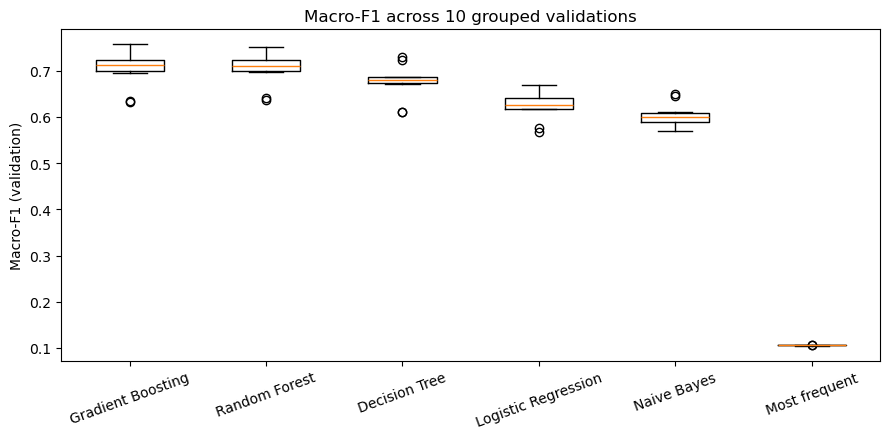

In [12]:
# Spread of the selected configuration of every model across the 10 validations.
order = summary["key"].tolist()
figure, axis = plt.subplots(figsize=(9, 4.5))
axis.boxplot([searches[k]["split_f1_macro"] for k in order], tick_labels=[searches[k]["name"].split(" (")[0] for k in order])
axis.set(ylabel="Macro-F1 (validation)", title=f"Macro-F1 across {len(splits)} grouped validations")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
figure.savefig(OUTPUTS / "cv_f1_macro_boxplot.png", dpi=150)
plt.show()